# 02 · Conditional Probability and Bayes' Theorem

**Covers:** Lab Exercise 2 (medical test) and Assignment 2 (two dice, spam filter, Simpson's paradox).

Formulas used in this notebook:

| Rule | Formula |
|---|---|
| Conditional probability | $P(A\mid B) = \dfrac{P(A\cap B)}{P(B)}$ |
| Product rule | $P(A\cap B) = P(A\mid B)\,P(B)$ |
| Total probability | $P(A) = \sum_i P(A\mid B_i)\,P(B_i)$ |
| Bayes | $P(H\mid E) = \dfrac{P(E\mid H)P(H)}{P(E\mid H)P(H) + P(E\mid\lnot H)P(\lnot H)}$ |
| Independence | $P(A\cap B) = P(A)P(B) \iff P(A\mid B) = P(A)$ |

In [1]:
%pip install -q numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd                     # tables (Simpson's paradox)
import matplotlib.pyplot as plt
from fractions import Fraction          # exact fractions like 2/9 instead of 0.2222
from itertools import product           # all combinations of two dice
from pathlib import Path

FIG = Path("figures")
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(42)

## Exercise 1 · The medical test (Lab 2)

Disease B with prevalence $P(B) = 0.01$. Sensitivity $P(+\mid B) = 0.95$,
specificity $P(-\mid\lnot B) = 0.90$, so the false-positive rate is $P(+\mid\lnot B) = 0.10$.

**a)** By Bayes:

$$P(B\mid +) = \frac{0.95\cdot 0.01}{0.95\cdot 0.01 + 0.10\cdot 0.99} = \frac{0.0095}{0.1085} \approx 0.0876$$

Only **≈ 8.8 %**! The disease is so rare that the false positives (10 % of the 99 %
healthy people = 9.9 % of everyone) are far more numerous than the true positives
(0.95 % of everyone).

**c)** Minimum specificity $s$ so that $P(B\mid +) \ge 0.5$:

$$0.95\cdot0.01 \ge (1-s)\cdot 0.99 \iff s \ge 1 - \frac{0.0095}{0.99} \approx 0.9904$$

In [3]:
prevalence, sensitivity, specificity = 0.01, 0.95, 0.90

def p_disease_given_positive(spec):
    """Bayes' theorem for the medical test, as a function of the specificity."""
    true_pos = sensitivity * prevalence              # P(+ and B)
    false_pos = (1 - spec) * (1 - prevalence)        # P(+ and not B)
    return true_pos / (true_pos + false_pos)         # P(B | +)

print(f"a) theoretical P(B|+) = {p_disease_given_positive(specificity):.4f}")

a) theoretical P(B|+) = 0.0876


In [4]:
# b) Simulate a whole population and look only at the people who tested positive.
N = 1_000_000
sick = rng.random(N) < prevalence                    # True with probability 0.01
# For each person: if sick, positive with prob. 0.95; if healthy, positive with prob. 0.10
positive = np.where(sick, rng.random(N) < sensitivity, rng.random(N) < 1 - specificity)

# P(B | +) = fraction of sick people AMONG the positives
print(f"b) simulated P(B|+) = {sick[positive].mean():.4f}   ({positive.sum():,} positive tests)")

# c) minimum specificity
spec_min = 1 - sensitivity * prevalence / (1 - prevalence)
print(f"c) minimum specificity = {spec_min:.4f}  ->  P(B|+) = {p_disease_given_positive(spec_min):.3f}")

b) simulated P(B|+) = 0.0876   (108,612 positive tests)
c) minimum specificity = 0.9904  ->  P(B|+) = 0.500


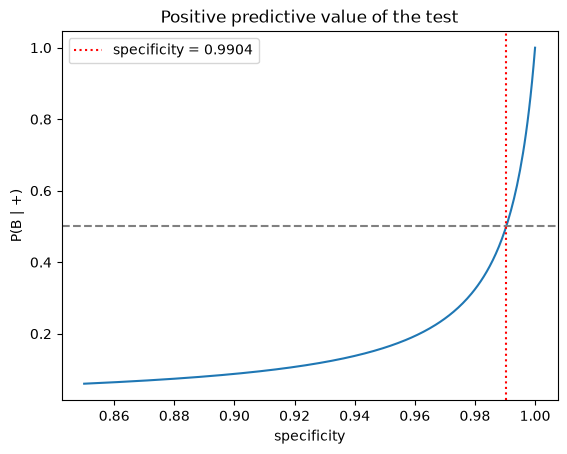

In [5]:
# Plot: how P(B|+) grows with the specificity
s = np.linspace(0.85, 1, 300)
plt.plot(s, p_disease_given_positive(s))
plt.axhline(0.5, ls="--", color="gray")
plt.axvline(spec_min, ls=":", color="red", label=f"specificity = {spec_min:.4f}")
plt.xlabel("specificity")
plt.ylabel("P(B | +)")
plt.title("Positive predictive value of the test")
plt.legend()
plt.savefig(FIG / "02_medical_test.png", dpi=150, bbox_inches="tight")
plt.show()

## Exercise 2 · Two dice (Assignment 2)

The sample space has 36 equally likely pairs (X, Y), so $P(A\mid B) = |A\cap B| / |B|$
(count the favourable cases inside B).

1. $P(X+Y\ge10 \mid X \text{ even})$: 18 cases with X even; favourable (4,6),(6,4),(6,5),(6,6) → **4/18 = 2/9**
2. $P(X+Y\ge10 \mid \text{at least one even})$: 27 cases; favourable (4,6),(6,4),(6,5),(5,6),(6,6) → **5/27**
3. $P(\text{both even} \mid X+Y=8)$: sum 8 has (2,6),(3,5),(4,4),(5,3),(6,2); both even in 3 → **3/5**
4. $A=\{X+Y\ge10\}$, $B=\{X \text{ even}\}$: $P(A) = 6/36 = 1/6 \ne P(A\mid B) = 2/9$ → **not independent**.

In [6]:
pairs = list(product(range(1, 7), repeat=2))     # the 36 outcomes (x, y)

def exact_conditional(event_A, event_B):
    """P(A | B) by counting: favourable cases inside B / number of cases in B."""
    cases_B = [w for w in pairs if event_B(w)]
    return Fraction(sum(event_A(w) for w in cases_B), len(cases_B))

# Events written as small functions of an outcome w = (x, y)
sum_ge_10 = lambda w: w[0] + w[1] >= 10
x_even = lambda w: w[0] % 2 == 0
some_even = lambda w: w[0] % 2 == 0 or w[1] % 2 == 0
both_even = lambda w: w[0] % 2 == 0 and w[1] % 2 == 0
sum_is_8 = lambda w: w[0] + w[1] == 8

exact = [exact_conditional(sum_ge_10, x_even),
         exact_conditional(sum_ge_10, some_even),
         exact_conditional(both_even, sum_is_8)]

# Simulation with 100,000 rolls: condition = keep only the rolls where B happened
X, Y = rng.integers(1, 7, 100_000), rng.integers(1, 7, 100_000)
S = X + Y
simulated = [np.mean(S[X % 2 == 0] >= 10),
             np.mean(S[(X % 2 == 0) | (Y % 2 == 0)] >= 10),
             np.mean(((X % 2 == 0) & (Y % 2 == 0))[S == 8])]

for name, e, sim in zip(["P(S>=10 | X even)", "P(S>=10 | some even)", "P(both even | S=8)"], exact, simulated):
    print(f"{name:22s} exact = {str(e):5s} = {float(e):.4f}   simulated = {sim:.4f}")

# 4) Independence test: compare P(A) with P(A | B)
p_A = Fraction(sum(sum_ge_10(w) for w in pairs), 36)
print(f"\nP(A) = {p_A},  P(A|B) = {exact[0]}  ->  independent? {p_A == exact[0]}")

P(S>=10 | X even)      exact = 2/9   = 0.2222   simulated = 0.2220
P(S>=10 | some even)   exact = 5/27  = 0.1852   simulated = 0.1845
P(both even | S=8)     exact = 3/5   = 0.6000   simulated = 0.5989

P(A) = 1/6,  P(A|B) = 2/9  ->  independent? False


## Exercise 3 · Spam filter with Naive Bayes (Assignment 2)

$P(S)=0.3$, $P(\text{offer}\mid S)=0.8$, $P(\text{offer}\mid\lnot S)=0.15$,
$P(\text{free}\mid S)=0.6$, $P(\text{free}\mid\lnot S)=0.1$.

1. $P(S\mid\text{offer}) = \dfrac{0.8\cdot0.3}{0.8\cdot0.3 + 0.15\cdot0.7} = \dfrac{0.24}{0.345}\approx 0.696$
2. Assuming the words are **conditionally independent given S**:
   $P(S\mid\text{offer},\text{free}) = \dfrac{0.8\cdot0.6\cdot0.3}{0.8\cdot0.6\cdot0.3 + 0.15\cdot0.1\cdot0.7} \approx 0.932$
3. Unrealistic because words are correlated even inside the same class
   ("free" and "offer" tend to appear together in the same kind of message).
4. Classification rule: label as spam if $P(S\mid\text{words}) > 0.5$
   (or a higher threshold if losing a real e-mail is costly).

In [7]:
p_spam = 0.3
p_offer = {"spam": 0.8, "ham": 0.15}     # P(offer | class)
p_free = {"spam": 0.6, "ham": 0.1}       # P(free  | class)

# 1) one word: numerator = P(offer | spam) P(spam); denominator = total probability of "offer"
num = p_offer["spam"] * p_spam
den = num + p_offer["ham"] * (1 - p_spam)
print(f"1) P(spam | offer)       = {num / den:.4f}")

# 2) two words, naive Bayes: multiply the likelihoods of each word
num = p_offer["spam"] * p_free["spam"] * p_spam
den = num + p_offer["ham"] * p_free["ham"] * (1 - p_spam)
print(f"2) P(spam | offer, free) = {num / den:.4f}")

1) P(spam | offer)       = 0.6957
2) P(spam | offer, free) = 0.9320


## Exercise 4 · Simpson's paradox (Assignment 2)

Inside **each** program course B has the higher pass rate, but after aggregating,
course A wins. Reason: course A is taken mostly in Program 1 (easy, 90 of A's 100
students) and course B mostly in Program 2 (hard, 80 of B's 100 students). The program
is a **confounding variable**.

In probabilities: $P(\text{pass}\mid B, P_k) > P(\text{pass}\mid A, P_k)$ for k = 1, 2, but

$$P(\text{pass}\mid A) = \sum_k P(\text{pass}\mid A, P_k)\,P(P_k\mid A)$$

uses weights $P(P_k\mid A)$ different from $P(P_k\mid B)$, so the order can flip.

In [8]:
# One row per (program, course) with passed / total
df = pd.DataFrame({
    "program": ["P1", "P1", "P2", "P2"],
    "course":  ["A",  "B",  "A",  "B"],
    "passed":  [81,   19,   1,    16],
    "total":   [90,   20,   10,   80],
})
df["rate"] = df.passed / df.total

# 1-2) pass rate of each course inside each program
print("Pass rate per program:")
print(df.pivot(index="program", columns="course", values="rate").round(3))

# 3) aggregated pass rate: add passed and total over the programs, then divide
agg = df.groupby("course")[["passed", "total"]].sum()
agg["rate"] = agg.passed / agg.total
print("\nAggregated pass rate:")
print(agg.round(3))

Pass rate per program:
course     A     B
program           
P1       0.9  0.95
P2       0.1  0.20

Aggregated pass rate:
        passed  total  rate
course                     
A           82    100  0.82
B           35    100  0.35


In [9]:
# Python extension: my own Simpson example (kidney-stone treatments, a classic data set)
mine = pd.DataFrame({
    "stone":     ["small", "small", "large", "large"],
    "treatment": ["T1",    "T2",    "T1",    "T2"],
    "success":   [81,      234,     192,     55],
    "total":     [87,      270,     263,     80],
})
mine["rate"] = mine.success / mine.total
print("Per group (T1 is better in BOTH groups):")
print(mine.pivot(index="stone", columns="treatment", values="rate").round(3))
g = mine.groupby("treatment")[["success", "total"]].sum()
print("\nAggregated (T2 looks better!):")
print((g.success / g.total).round(3))

Per group (T1 is better in BOTH groups):
treatment     T1     T2
stone                  
large      0.730  0.688
small      0.931  0.867

Aggregated (T2 looks better!):
treatment
T1    0.780
T2    0.826
dtype: float64


### Key takeaways
- Write the **denominator with the law of total probability** – that is where most mistakes happen.
- A rare condition + an imperfect test ⇒ low $P(B\mid +)$ (base-rate fallacy).
- Simulate a conditional probability by **filtering**: `np.mean(A[B])`.